# torchpalmm quickstart

`torchpalmm` fits **linear mixed models** and **additive smoothing-spline mixed models**
by REML in PyTorch, batched over groups (GPU-capable). This vignette walks through:

1. a plain linear mixed model + a fixed-effect *t*-test,
2. a smoothing-spline mixed model: fitting the smooth, plotting fitted vs. truth,
   a fixed-effect test, and a **linearity test** of the smooth (H0: the curve is linear).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # so `import torchpalmm` works without install

import numpy as np
import torch
import matplotlib.pyplot as plt

from torchpalmm import LinearMixedModel, SmoothingSplineMixed

torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(0)

## 1. Linear mixed model

Balanced panel: $y_{ij} = \beta_0 + \beta_1 x_{ij} + b_i + \varepsilon_{ij}$ with a
random intercept $b_i \sim N(0,\,0.7^2)$. We fit by REML and test $H_0:\beta_1 = 0$.

In [2]:
G, ni = 40, 8
beta = np.array([1.0, 0.5])                  # intercept, slope
X, Z, y, ids = [], [], [], []
for i in range(G):
    Xi = np.column_stack([np.ones(ni), rng.normal(size=ni)])   # [1, x]
    b  = rng.normal(scale=0.7)                                  # random intercept
    yi = Xi @ beta + b + rng.normal(scale=1.0, size=ni)
    X.append(Xi); Z.append(np.ones((ni, 1))); y.append(yi); ids += [i] * ni
X = np.vstack(X); Z = np.vstack(Z); y = np.concatenate(y)[:, None]; ids = np.array(ids)

lmm = LinearMixedModel(y=y, X=X, Z=Z, id=ids, corr_structure="iid", rand_D_type="diagonal")
lmm.fit_likelihood(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=300,
                   fit_type="REML", verbose=False)

# sigma2 is the residual covariance (nmax x nmax); for "iid" it is sigma^2 * I.
resid_var = float(lmm.sigma2.reshape(-1)[0])
print("estimated beta :", np.round(lmm.beta.ravel().tolist(), 3), " (true [1.0, 0.5])")
print("residual var   :", round(resid_var, 3))
print("slope t-test   :", lmm.fixed_t_test(1))   # H0: beta_1 = 0

estimated beta : [0.92  0.397]  (true [1.0, 0.5])
residual var   : 0.968


slope t-test   : {'estimate': 0.3965525680927517, 'se': 0.057243159083389214, 't': 6.927510194101483, 'df': 293.1632568607275, 'p_value': 2.7185587114786358e-11}


## 2. Smoothing-spline mixed model

Longitudinal data with a shared smooth curve, a fixed covariate, and a subject random
intercept:
$y_{ij} = \beta_x x_{ij} + f(t_{ij}) + b_i + \varepsilon_{ij}$, with the true
$f(t) = \sin(2\pi t)$. The linear part $[1, t]$ is added internally, so `X` holds only
the extra covariate(s).

In [3]:
f_true = lambda t: np.sin(2 * np.pi * t)
G, GRID, beta_x = 40, 30, 0.8
y, X, Z, sp, ids = [], [], [], [], []
for i in range(G):
    n = int(rng.integers(8, 14))
    t = np.sort(rng.integers(0, GRID, size=n)) / GRID
    x = rng.normal(size=n)
    b = rng.normal(scale=0.6)
    yi = beta_x * x + f_true(t) + b + rng.normal(scale=0.5, size=n)
    y.append(yi); X.append(x); Z.append(np.ones(n)); sp.append(t); ids += [i] * n
y = np.concatenate(y); X = np.concatenate(X)[:, None]; Z = np.concatenate(Z)[:, None]
sp = np.concatenate(sp); ids = np.array(ids)

# y, X, Z, sp, ids may all be plain numpy arrays -- converted internally.
ssm = SmoothingSplineMixed(y=y, X=X, Z=Z,
                           spline_inputs=sp, obs_id=ids,
                           corr_structure="iid", rand_D_type="diagonal")
ssm.fit(optimizer=torch.optim.LBFGS, lr=1.0, max_iter=200, fit_type="reml", verbose=False)

### Fitted smooth vs. truth

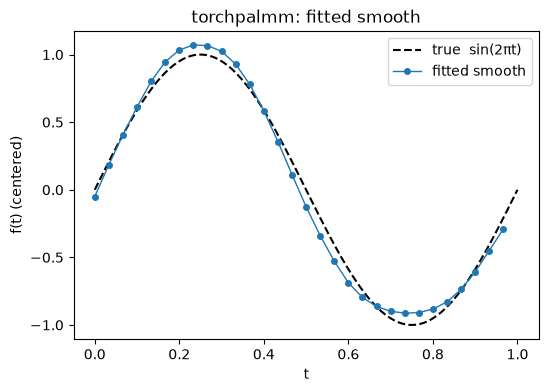

In [4]:
fitted, _ = ssm.get_blup()
fc = fitted[fitted.spline_id == 0].sort_values("spline_var")
t_fit  = fc["spline_var"].to_numpy()
f_fit  = fc["theta_fitted"].to_numpy()
f_fit = f_fit - f_fit.mean()                         # center (overall intercept is absorbed)

grid = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 4))
plt.plot(grid, f_true(grid) - f_true(grid).mean(), "k--", lw=1.5, label="true  sin(2πt)")
plt.plot(t_fit, f_fit, "o-", lw=1, ms=4, label="fitted smooth")
plt.xlabel("t"); plt.ylabel("f(t) (centered)"); plt.legend(); plt.title("torchpalmm: fitted smooth")
plt.show()

### Inference

In [5]:
# Fixed-effect test on the covariate x (column 0 of X):
print("covariate x  t-test :", ssm.fixed_t_test(0))

# Linearity test of the smooth (H0: tau^2 = 0, i.e. f is linear) -- here f is sin, so reject:
print("linearity test       :", ssm.linearity_test(s=0))

covariate x  t-test : {'estimate': 0.8071086752983978, 'se': 0.025564147892465982, 't': 31.57189821829583, 'df': 386.42695746967087, 'p_value': 0.0}
linearity test       : {'statistic': 26.63248925262506, 'scale_a': 0.7258084644491658, 'df': 1.3955143892718098, 'p_value': 3.3803140238601392e-09, 'spline_id': 0, 'reject': True}


The covariate test should reject (true $\beta_x = 0.8$), and the linearity test
should reject (the truth is a genuine curve, not a line). Swap `f_true` for a straight
line to see the linearity test *fail to reject* instead.